In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# split_type = 'simple'
split_type = 'mcquery'

In [3]:
# REMEMBER TO CHANGE CACHED DATAFRAMES PATH

file_type = 'zppresel'
# file_type = 'nuepresel'

In [4]:
import sys, os 
from data_loading import load_runs
from microfit.histogram import Binning, Histogram, RunHistGenerator

if file_type=='zppresel':
    RUN = ["4a_zppresel_75testsplit_75split", "4b_zppresel_75testsplit_75split", "4c_zppresel_75testsplit_75split", "4d_zppresel_75testsplit_75split", "5_zppresel_75testsplit_75split"]
    rundata, mc_weights, data_pot = load_runs(
        RUN,
        data="bnb",
        truth_filtered_sets=["nue", "drt", "nc_pi0"],
        use_truth_filters=False,
        loadpi0variables=True,
        loadshowervariables=True,
        loadrecoveryvars=True,
        loadsystematics=False,    # Set to false when we don't have event weights
        load_crt_vars=True,
        use_bdt = True,
        use_bdt_stacked=True,
        load_lee=False,
        enable_cache=True,
        blinded=True,
    )
if file_type=='nuepresel':
    RUN = ["4d_nuepresel_75testsplit_75split", "5_nuepresel_75testsplit_75split"]
    rundata, mc_weights, data_pot = load_runs(
        RUN,
        data="bnb",
        truth_filtered_sets=["nue", "drt", "nc_pi0"],
        use_truth_filters=False,
        loadpi0variables=True,
        loadshowervariables=True,
        loadrecoveryvars=True,
        loadsystematics=False,    # Set to false when we don't have event weights
        load_crt_vars=True,
        use_bdt = True,
        use_bdt_stacked=True,
        load_lee=False,
        enable_cache=True,
        blinded=True,
    )

Loading run 4a_zppresel_75testsplit_75split
Loading run 4b_zppresel_75testsplit_75split
Loading run 4c_zppresel_75testsplit_75split
Loading run 4d_zppresel_75testsplit_75split
Loading run 5_zppresel_75testsplit_75split


In [5]:
df_nu=rundata["mc"]
df_nue=rundata["nue"]
df_dirt=rundata["drt"]
df_ncpi0=rundata["nc_pi0"]
df_ext=rundata["ext"]

In [6]:
# import pandas as pd

# pd.set_option('display.max_rows', None)

# print(df_nue["category"])
# # print(df_nue["is_signal"])

In [7]:
# print(data_loading.py)

In [8]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Split dataframes into training and testing samples
if split_type == 'simple':
    train_nu, test_nu = train_test_split(df_nu, test_size=0.5, random_state=1990)
    train_nue_truth, test_nue = train_test_split(df_nue, test_size=0.5, random_state=1990)
    train_dirt, test_dirt = train_test_split(df_dirt, test_size=0.5, random_state=1990)
    train_ncpi0_truth, test_ncpi0 = train_test_split(df_ncpi0, test_size=0.5, random_state=1990)
    train_ext, test_ext = train_test_split(df_ext, test_size=0.5, random_state=1990)

# if split_type == 'mcquery':
#     train_nue_truth, test_nue = train_test_split(df_nue, test_size=0.5, random_state=1990)
#     train_dirt, test_dirt = train_test_split(df_dirt, test_size=0.5, random_state=1990)
#     train_ncpi0_truth, test_ncpi0 = train_test_split(df_ncpi0, test_size=0.5, random_state=1990)
#     train_ext, test_ext = train_test_split(df_ext, test_size=0.5, random_state=1990)

if split_type == 'mcquery':
    train_nue_truth, test_nue = train_test_split(df_nue, test_size=0.75, random_state=1990)
    train_dirt, test_dirt = train_test_split(df_dirt, test_size=0.75, random_state=1990)
    train_ncpi0_truth, test_ncpi0 = train_test_split(df_ncpi0, test_size=0.75, random_state=1990)
    train_ext, test_ext = train_test_split(df_ext, test_size=0.75, random_state=1990)

In [9]:
if split_type == 'mcquery':
    # Separate CC Nue events from nu overlay
    NUEQUERY = '(abs(nu_pdg)==12 & ccnc==0)'
    nu_ccnue = df_nu.query(NUEQUERY)

    # Separate NC Pi0 events from nu overlay
    NCPI0QUERY = '(mcf_pass_ncpi0==1)'
    nu_ncpi0 = df_nu.query(NCPI0QUERY)

    # Get sample that doesn't have CC Nue or NC Pi0 events (basically take the opposite of the previous two queries combined)
    MCQUERY = '((abs(nu_pdg)==12 & ccnc==0) | mcf_pass_ncpi0==1)'
    nu_no_ccnue_ncpi0 = df_nu.query('~'+MCQUERY)

    # Split this new nu overlay sample into training and testing samples
    train_nu, test_nu = train_test_split(nu_no_ccnue_ncpi0, test_size=0.75, random_state=1990)

    # Add CC nue and NC pi0 events into their respective truth training samples
    train_nue = pd.concat([train_nue_truth, nu_ccnue], ignore_index=True)
    train_ncpi0 = pd.concat([train_ncpi0_truth, nu_ncpi0], ignore_index=True)

In [10]:
# second_split_type = 'simple'
second_split_type = 'nuequery'

In [11]:
if second_split_type == 'simple':
    train_nu_25p, test_nu_25p = train_test_split(test_nu, test_size = 0.5, random_state=1990)
    train_nue_25p, test_nue_25p = train_test_split(test_nue, test_size = 0.5, random_state=1990)
    train_dirt_25p, test_dirt_25p = train_test_split(test_dirt, test_size = 0.5, random_state=1990)
    train_ncpi0_25p, test_ncpi0_25p = train_test_split(test_ncpi0, test_size = 0.5, random_state=1990)
    train_ext_25p, test_ext_25p = train_test_split(test_ext, test_size = 0.5, random_state=1990)

# if second_split_type == 'nuequery':
#     train_nu_25p, test_nu_25p = train_test_split(test_nu, test_size = 0.5, random_state=1990)
#     train_dirt_25p, test_dirt_25p = train_test_split(test_dirt, test_size = 0.5, random_state=1990)
#     train_ncpi0_25p, test_ncpi0_25p = train_test_split(test_ncpi0, test_size = 0.5, random_state=1990)
#     train_ext_25p, test_ext_25p = train_test_split(test_ext, test_size = 0.5, random_state=1990)

if second_split_type == 'nuequery':
    train_nu_25p, test_nu_25p = train_test_split(test_nu, test_size = 0.75, random_state=1990)
    train_dirt_25p, test_dirt_25p = train_test_split(test_dirt, test_size = 0.75, random_state=1990)
    train_ncpi0_25p, test_ncpi0_25p = train_test_split(test_ncpi0, test_size = 0.75, random_state=1990)
    train_ext_25p, test_ext_25p = train_test_split(test_ext, test_size = 0.75, random_state=1990)

In [12]:
if second_split_type == 'nuequery':
    SIGNALQUERY = 'category == 10'
    BKGQUERY = 'category != 10'

    nue_signal = test_nue.query(SIGNALQUERY)
    nue_bkg = test_nue.query(BKGQUERY)

    train_nue_signal, test_nue_signal = train_test_split(nue_signal, test_size = 0.75, random_state=1990)
    train_nue_bkg, test_nue_bkg = train_test_split(nue_bkg, test_size = 0.75, random_state=1990)

    test_nue_25p = pd.concat([test_nue_signal, test_nue_bkg], ignore_index=True)

In [13]:
crt_vars = [
    ("crtveto", 2, (0,2), "crtveto"),
    ("crtveto", 1, (0,2), "crtveto"),
    ("_closestNuCosmicDist", 20, (0, 100), "_closestNuCosmicDist"),
]

second_shr = [
    ("shr_energy_tot_cali", 16, (0, 4), "shr_energy_tot_cali"),
    ("anglediff_U", 25, (0, 300), "anglediff_U"),
    ("secondshower_U_dot", 25, (0, 1), "secondshower_U_dot"),
    ("secondshower_U_nhit", 25, (0, 100), "secondshower_U_nhit"),
    ("secondshower_U_vtxdist", 25, (0, 200), "secondshower_U_vtxdist"),
    ("anglediff_V", 25, (0, 300), "anglediff_V"),
    ("secondshower_V_dot", 25, (0, 1), "secondshower_V_dot"),
    ("secondshower_V_nhit", 25, (0, 100), "secondshower_V_nhit"),
    ("secondshower_V_vtxdist", 25, (0, 200), "secondshower_V_vtxdist"),
    ("anglediff_Y", 25, (0, 300), "anglediff_Y"),
    ("secondshower_Y_dot", 25, (0, 1), "secondshower_Y_dot"),
    ("secondshower_Y_nhit", 25, (0, 100), "secondshower_Y_nhit"),
    ("secondshower_Y_vtxdist", 25, (0, 200), "secondshower_Y_vtxdist"),
]


dedx_vars = [
    ("shr_dedx_Y", 25, (0, 10), "shr_dedx_Y"),
    ("shr_tkfit_dedx_U", 25, (0, 10), "shr_tkfit_dedx_U"),
    ("shr_tkfit_dedx_V", 25, (0, 10), "shr_tkfit_dedx_V"),
    ("shr_tkfit_dedx_Y", 25, (0, 10), "shr_tkfit_dedx_Y"),
    ("shr_tkfit_gap10_dedx_U", 25, (0, 10), "shr_tkfit_gap10_dedx_U"),
    ("shr_tkfit_gap10_dedx_V", 25, (0, 10), "shr_tkfit_gap10_dedx_V"),
    ("shr_tkfit_gap10_dedx_Y", 25, (0, 10), "shr_tkfit_gap10_dedx_Y"),
    ("shr_tkfit_2cm_dedx_U", 25, (0, 10), "shr_tkfit_2cm_dedx_U"),
    ("shr_tkfit_2cm_dedx_V", 25, (0, 10), "shr_tkfit_2cm_dedx_V"),
    ("shr_tkfit_2cm_dedx_Y", 25, (0, 10), "shr_tkfit_2cm_dedx_Y"),
    ("shr_tkfit_dedx_max", 25, (0, 10), "shr_tkfit_dedx_max"),
    ("shr_tkfit_2cm_dedx_max", 25, (0, 10), "shr_tkfit_2cm_dedx_max"),
    ("shr_tkfit_gap10_dedx_max", 25, (0, 10), "shr_tkfit_gap10_dedx_max"),
    # ("shr_dedx_Y", 25, (7, 30), "shr_dedx_Y"),
    # ("shr_tkfit_dedx_U", 25, (7, 30), "shr_tkfit_dedx_U"),
    # ("shr_tkfit_dedx_V", 25, (7, 30), "shr_tkfit_dedx_V"),
    # ("shr_tkfit_dedx_Y", 25, (7, 30), "shr_tkfit_dedx_Y"),
    # ("shr_tkfit_gap10_dedx_U", 25, (7, 30), "shr_tkfit_gap10_dedx_U"),
    # ("shr_tkfit_gap10_dedx_V", 25, (7, 30), "shr_tkfit_gap10_dedx_V"),
    # ("shr_tkfit_gap10_dedx_Y", 25, (7, 30), "shr_tkfit_gap10_dedx_Y"),
    # ("shr_tkfit_2cm_dedx_U", 25, (7, 30), "shr_tkfit_2cm_dedx_U"),
    # ("shr_tkfit_2cm_dedx_V", 25, (7, 30), "shr_tkfit_2cm_dedx_V"),
    # ("shr_tkfit_2cm_dedx_Y", 25, (7, 30), "shr_tkfit_2cm_dedx_Y"),
]

zp_variables_loose_bdt = [
    ("slice_orig_pass_id", 1, (0, 2), "slice_orig_pass_id"),
    ("CosmicIPAll3D", 25, (0, 300), "CosmicIPAll3D"),
    ("CosmicIPAll3D", 25, (0, 50), "CosmicIPAll3D"),
    ("CosmicDirAll3D", 25, (-1, 1), "CosmicDirAll3D"),
    ("CosmicDirAll3D", 25, (0, 1), "CosmicDirAll3D"),
    ("shrmoliereavg", 25, (0, 50), "shrmoliereavg"),
    ("subcluster", 25, (0, 70), "subcluster"),
    ("subcluster", 10, (0, 20), "subcluster"),
    ("trkfit", 25, (0, 1), "trkfit"),
    ("secondshower_Y_nhit", 25, (0, 100), "secondshower_Y_nhit"),
    ("secondshower_Y_nhit", 25, (20, 100), "secondshower_Y_nhit"),
    ("shr_trk_sce_start_y", 25, (-150, 150), "shr_trk_sce_start_y"),
    ("shr_trk_sce_end_y", 25, (-150, 150), "shr_trk_sce_end_y"),
    ("shr_trk_len", 25, (0, 200), "shr_trk_len"),
    ("shr_trk_len", 25, (80, 300), "shr_trk_len"),
    ("shr_trk_len", 25, (0, 40), "shr_trk_len"),
    ("tk1sh1_angle_alltk", 25, (-1.2, 1.2), "tk1sh1_angle_alltk"),
    ("CylFrac2h_1cm", 25, (0, 1), "CylFrac2h_1cm"),
    ("CylFrac2h_1cm", 25, (0.3, 0.7), "CylFrac2h_1cm"),
    ("CylFrac2h_1cm", 25, (0.2, 1), "CylFrac2h_1cm"),
    ("DeltaRMS2h", 25, (-0.5, 30), "DeltaRMS2h"),
    ("DeltaRMS2h", 25, (0, 10), "DeltaRMS2h"),
    ("DeltaRMS2h", 25, (10, 30), "DeltaRMS2h"),
    ("shrMCSMom", 25, (0, 400), "shrMCSMom"),
    ("shrMCSMom", 25, (0, 50), "shrMCSMom"),
    ("shrMCSMom", 25, (200, 600), "shrMCSMom"),
    ("shrPCA1CMed_5cm", 25, (0, 1), "shrPCA1CMed_5cm"),
    ("shr_score", 25, (-0.1, 0.1), "shr_score"),
    ("shr_tkfit_2cm_dedx_U", 25, (0, 8), "shr_tkfit_2cm_dedx_U"),
    ("shr_tkfit_2cm_dedx_V", 25, (0, 8), "shr_tkfit_2cm_dedx_V"),
    ("shr_tkfit_2cm_dedx_Y", 25, (0, 8), "shr_tkfit_2cm_dedx_Y"),
    ("shr_tkfit_gap10_dedx_U", 25, (0, 8), "shr_tkfit_gap10_dedx_U"),
    ("shr_tkfit_gap10_dedx_V", 25, (0, 8), "shr_tkfit_gap10_dedx_V"),
    ("shr_tkfit_gap10_dedx_Y", 25, (0, 8), "shr_tkfit_gap10_dedx_Y"),
    ("diffY", 25, (-95, 95), "ChargeY - FlashY [cm]"),
    ("normdiffY", 25, (-2.3, 2.3), "(ChargeY - FlashY) / FlashwidthY"),
    ("diffZ", 25, (-115, 115), "ChargeZ - FlashZ [cm]"),
    ("normdiffZ", 25, (-1.0, 1.0), "(ChargeZ - FlashZ) / FlashwidthZ"),
    ("fnl", 25, (-320, 120), "m.log(Charge/Flash) - ChargeX"),
]

nugraph_vars = [
    ("slice_orig_pass_id", 1, (0, 2), "slice_orig_pass_id"),
    ("slcng2mip", 20, (0, 100), "slcng2mip"),
    # ("slcng2mip", 20, (10, 300), "slcng2mip"),
    ("slcng2hip", 20, (0, 100), "slcng2hip"),
    # ("slcng2hip", 20, (10, 150), "slcng2hip"),
    ("slcng2shr", 20, (0, 500), "slcng2shr"),
    ("slcng2mcl", 20, (0, 100), "slcng2mcl"),
    # ("slcng2mcl", 20, (10, 175), "slcng2mcl"),
    ("slcng2dfs", 20, (0, 300), "slcng2dfs"),
    ("slcng2bkg", 20, (0, 100), "slcng2bkg"),
    # ("slcng2bkg", 20, (10, 300), "slcng2bkg"),
    ("clung2mip", 20, (0, 100), "clung2mip"),
    # ("clung2mip", 20, (10, 300), "clung2mip"),
    ("clung2hip", 20, (0, 100), "clung2hip"),
    # ("clung2hip", 20, (10, 150), "clung2hip"),
    ("clung2shr", 20, (0, 500), "clung2shr"),
    ("clung2mcl", 20, (0, 100), "clung2mcl"),
    # ("clung2mcl", 20, (10, 100), "clung2mcl"),
    ("clung2dfs", 20, (0, 200), "clung2dfs"),
    # ("clung2dfs", 20, (10, 200), "clung2dfs"),
    # ("clung2bkg", 20, (0, 300), "clung2bkg"),
    ("clung2bkg", 20, (0, 100), "clung2bkg"),
    ("nhits_r1cm", 20, (0, 50), "nhits_r1cm"),
    ("nhits_r3cm", 20, (0, 150), "nhits_r3cm"),
    ("nhits_r5cm", 20, (0, 200), "nhits_r5cm"),
    ("nhits_r10cm", 20, (0, 300), "nhits_r10cm"),
    ("ng2hip_r1cm", 20, (0, 25), "ng2hip_r1cm"),
    ("ng2hip_r3cm", 20, (0, 50), "ng2hip_r3cm"),
    ("ng2hip_r5cm", 20, (0, 50), "ng2hip_r5cm"),
    ("ng2hip_r10cm", 20, (0, 100), "ng2hip_r10cm"),
    ("ng2clu_hip_r1cm", 20, (0, 25), "ng2clu_hip_r1cm"),
    ("ng2clu_hip_r3cm", 20, (0, 50), "ng2clu_hip_r3cm"),
    ("ng2clu_hip_r5cm", 20, (0, 50), "ng2clu_hip_r5cm"),
    ("ng2clu_hip_r10cm", 20, (0, 50), "ng2clu_hip_r10cm"),
    ("ng2clu_hippfp_r1cm", 20, (0, 10), "ng2clu_hippfp_r1cm"),
    ("ng2clu_hippfp_r3cm", 20, (0, 10), "ng2clu_hippfp_r3cm"),
    ("ng2clu_hippfp_r5cm", 20, (0, 10), "ng2clu_hippfp_r5cm"),
    ("ng2clu_hippfp_r10cm", 20, (0, 10), "ng2clu_hippfp_r10cm"),
]

slice_var = [
    # ("slice_orig_pass_id", 1, (0, 2), "slice_orig_pass_id"),
    ("shr_energy_tot_cali", 10, (0, 4), "shr_energy_tot_cali"),
    # ("shr_energy_tot_cali", 10, (3, 4), "shr_energy_tot_cali"),
]

bdt_vars = [
    ("bkg_score", 20, (0, 1), "bkg_score"),
    ("pi0_score", 20, (0, 1), "pi0_score"),
    ("nonpi0_score", 20, (0, 1), "nonpi0_score"),
]

proton_vars = [
    ("proton_e", 20, (0,2), "proton_e"),
    ("trk_theta", 20, (-100,100), "trk_theta"),
    ("trk_distance", 20, (0,100), "trk_distance"),
    ("trk_energy", 20, (0,1), "trk_energy"),
    ("tksh_distance", 20, (0,100), "tksh_distance"),
    ("tksh_angle", 20, (-100,100), "tksh_angle"),
    ("trk_hits_tot", 20, (0,10), "trk_hits_tot"),
    ("trk_len", 20, (0,100), "trk_len"),
]

loosesel_variables_1eNp = [
    ("hits_ratio", 20, (0, 1), "hits_ratio, shower hits/all hits"),
    ("trkfit", 20, (0, 1.0), "trkfit, Fraction of Track-fitted points"),
    ("subcluster", 20, (0, 100), "subcluster, N sub-clusters in shower"),
    ("CosmicIPAll3D", 20, (0, 200), "CosmicIPAll3D [cm]"),
    ("shr_tkfit_dedx_max", 20, (0, 10), "shr tkfit dE/dx (max, 0-4 cm) [MeV/cm]"),
    ("tksh_angle", 20, (-1, 1), "tksh_angle, cos(trk-shr angle)"),
    ("tksh_distance", 20, (0, 40), "tksh_distance, trk-shr distance [cm]"),
    ("shr_tkfit_nhits_tot", 20, (0, 40), "shr tkfit nhits (tot, 0-4 cm) [MeV/cm]"),
    ("trkpid", 21, (-1, 1), "trkpid, track LLR PID"),
    ("shrmoliereavg", 20, (0, 20), "shrmoliereavg, average Moliere angle [degrees]"),
    ("shr_trk_len", 40, (0, 200), "shr_trk_len, Shower track fit length [cm]"),
    # ("nonpi0_score", 10, (0, 1.0), "BDT non-$\\pi^0$ score", "log", True),
    # ("pi0_score", 10, (0, 1.0), "BDT $\\pi^0$ score", "log", True),
    # ("bkg_score", 10, (0, 1.0), "1e0p BDT score", "log", True),
]

trksel_variables = [
    ("tksh_angle", 20, (-1, 1), "cos(trk-shr angle)"),
    ("trkshrhitdist2", 20, (0, 10), "2D trk-shr distance (Y)"),
    ("tksh_distance", 20, (0, 40), "trk-shr distance [cm]"),
    # ('tksh_distance',12,(0,6),"trk-shr distance [cm]","zoomed")
    ("trkpid", 21, (-1, 1), "track LLR PID"),
    # ('trkpid',2,(-1,1),"track LLR PID", 'twobins'),
    # ('trkpid',15,(-1,1),"track LLR PID","coarse")
]

trkreco_vars = [
    ("shr_energy_tot_cali", 10, (0, 4), "shr_energy_tot_cali"),
    ("protonenergy_corr", 20, (0,1), "protonenergy_corr, proton kinetic energy"),
    ("cos_trk_theta", 20, (-1.1,1.1), "cos_trk_theta, cosine of proton angle wrt beam"),
    ("n_tracks_contained", 4, (0, 4), "n_tracks_contained"),
    ("tksh_angle", 20, (-1.1, 1.1), "trksh_angle, cos(trk-shr angle)"),
    # ("ng2hip_r1cm", 20, (0, 20), "ng2hip_r1cm"),
    # ("ng2hip_r3cm", 20, (0, 40), "ng2hip_r3cm"),
    # ("ng2hip_r5cm", 20, (0, 40), "ng2hip_r5cm"),
    # ("ng2hip_r10cm", 20, (0, 40), "ng2hip_r10cm"),
    # ("ng2clu_hip_r1cm", 20, (0, 5), "ng2clu_hip_r1cm"),
    # ("ng2clu_hip_r3cm", 20, (0, 10), "ng2clu_hip_r3cm"),
    # ("ng2clu_hip_r5cm", 20, (0, 10), "ng2clu_hip_r5cm"),
    # ("ng2clu_hip_r10cm", 20, (0, 10), "ng2clu_hip_r10cm"),
    # ("ng2clu_hippfp_r1cm", 20, (0, 1), "ng2clu_hippfp_r1cm"),
    # ("ng2clu_hippfp_r3cm", 20, (0, 1), "ng2clu_hippfp_r3cm"),
    # ("ng2clu_hippfp_r5cm", 20, (0, 1), "ng2clu_hippfp_r5cm"),
    # ("ng2clu_hippfp_r10cm", 20, (0, 1), "ng2clu_hippfp_r10cm"),
    # ("slcng2hip", 20, (0, 60), "slcng2hip"),
    # ("clung2hip", 20, (0, 60), "clung2hip"),
]

trueproton_vars = [
    ("proton_ke", 20, (0, 0.3), "proton_ke"),
    ("proton_pz", 20, (-1, 1), "proton_pz"),
    ("nproton", 4, (0, 4), "nproton"),
]

trk_true_reco = [
    ("shr_energy_tot_cali", 10, (0, 4), "shr_energy_tot_cali"),
    ("protonenergy_corr", 20, (0,1), "protonenergy_corr, proton kinetic energy"),
    ("cos_trk_theta", 20, (-1.1,1.1), "cos_trk_theta, cosine of proton angle wrt beam"),
    ("n_tracks_contained", 4, (0, 4), "n_tracks_contained"),
    ("tksh_angle", 20, (-1.1, 1.1), "trksh_angle, cos(trk-shr angle)"),
    ("proton_ke", 20, (0, 0.2), "proton_ke"),
    ("proton_ke", 20, (0, 0.5), "proton_ke"),
    # ("proton_ke", 20, (0.05, 0.5), "proton_ke"),
    ("proton_pz", 20, (-1, 1), "proton_pz"),
    ("nproton", 4, (0, 4), "nproton"),
]

slice_variables_slicecut = [
    ("diffY", 25, (-95, 95), "ChargeY - FlashY [cm]"),
    ("normdiffY", 25, (-2.3, 2.3), "(ChargeY - FlashY) / FlashwidthY"),
    ("diffZ", 25, (-115, 115), "ChargeZ - FlashZ [cm]"),
    ("normdiffZ", 25, (-1.0, 1.0), "(ChargeZ - FlashZ) / FlashwidthZ"),
    ("fnl", 25, (-320, 120), "m.log(Charge/Flash) - ChargeX"),
]

bdt_2bdts_vars = [
    ("shr_energy_tot_cali", 15, (0, 4.5), "shr_energy_tot_cali"),
    ("bkg_score", 20, (0, 1), "bkg_score"),
    ("pi0_score", 20, (0, 1), "pi0_score"),
    ("pi0_score", 8, (0.8, 1), "pi0_score"),
    ("pi0_score", 10, (0.9, 1), "pi0_score"),
    ("nonpi0_score", 20, (0, 1), "nonpi0_score"),
    ("nonpi0_score", 8, (0.8, 1), "nonpi0_score"),
    ("nonpi0_score", 20, (0.9, 1), "nonpi0_score"),
    ("np_score", 20, (0, 1), "np_score"),
    ("np_score", 30, (0.4, 1), "np_score"),
]

np_bdt_vars = [
    ("bkg_Np_score", 20, (0, 1), "bkg_Np_score"),
    ("pi0_Np_score", 20, (0, 1), "pi0_Np_score"),
    ("nonpi0_Np_score", 20, (0, 1), "nonpi0_Np_score"),
]

shr_kinematics = [
    # ("cos_shr_theta", 8, (-1, 1), "cos_shr_theta"),
    # ("cos_shr_theta", 20, (-1, 1), "cos_shr_theta"),
    # ("cos_shr_theta", 8, (-1, 0.5), "cos_shr_theta"),
    # ("cos_shr_theta", 8, (-1, 0.75), "cos_shr_theta"),
    ("cos_shr_theta", 2, (-1, 1), "cos_shr_theta", False, "Binning Label", [-1, 0.9, 1]),
    ("cos_shr_theta", 2, (-1, 1), "cos_shr_theta", False, "Binning Label", [-1, 0.935, 1]),
    ("cos_shr_theta", 2, (-1, 1), "cos_shr_theta", False, "Binning Label", [-1, 0.94, 1]),
    # ("cos_shr_theta", 1, (-1, 0.94), "cos_shr_theta"),
    # ("cos_shr_theta", 1, (0.94, 1), "cos_shr_theta"),
    # ("shr_energy_tot_cali", 20, (0, 4), "shr_energy_tot_cali"),
    # ("shr_energy_tot_cali", 10, (0, 1), "shr_energy_tot_cali"),
    # ("shr_energy_tot_cali", 4, (0, 1), "shr_energy_tot_cali"),
    # ("shr_energy_tot_cali", 2, (0, 4.5), "shr_energy_tot_cali", False, "Binning Label", [0, 0.65, 4.5]),
    # ("shr_energy_tot_cali", 1, (0, 0.65), "shr_energy_tot_cali"),
    # ("shr_energy_tot_cali", 1, (0.65, 4.5), "shr_energy_tot_cali"),
    # ("electron_e", 15, (0, 4.5), "electron_e"),
    # ("electron_e", 10, (0, 1), "electron_e"),
    # ("electron_e", 4, (0, 1), "electron_e"),
    ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 0.9, 4.5]),
    ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 0.95, 4.5]),
    ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 1, 4.5]),
    ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 1.15, 4.5])
    # ("electron_e", 1, (0, 0.95), "electron_e"),
    # ("electron_e", 1, (0.95, 4.5), "electron_e"),
    # ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 0.9, 4.5]),
    # ("electron_e", 1, (0, 0.9), "electron_e"),
    # ("electron_e", 1, (0.9, 4.5), "electron_e"),
]

In [14]:
# varSet = crt_vars
# varSet = second_shr
# varSet = dedx_vars
# varSet = zp_variables_loose_bdt
# varSet = nugraph_vars
# varSet = slice_var
# varSet = slice_variables_slicecut
# varSet = bdt_vars
# varSet = proton_vars
# varSet = loosesel_variables_1eNp
# varSet = trksel_variables
# varSet = trkreco_vars
# varSet = trueproton_vars
# varSet = trk_true_reco
# varSet = bdt_2bdts_vars
# varSet = np_bdt_vars
varSet = shr_kinematics

In [15]:
zpquery = 'category == 10'
bkgquery = 'category != 10'

In [16]:
signal_test_nu_25p = test_nu_25p.query(zpquery)
signal_test_nue_25p = test_nue_25p.query(zpquery)
signal_test_dirt_25p = test_dirt_25p.query(zpquery)
signal_test_ncpi0_25p = test_ncpi0_25p.query(zpquery)
signal_test_ext_25p = test_ext_25p.query(zpquery)

In [17]:
rundata["mc"]=signal_test_nu_25p
rundata["nue"]=signal_test_nue_25p
rundata["drt"]=signal_test_dirt_25p
rundata["nc_pi0"]=signal_test_ncpi0_25p
rundata["ext"]=signal_test_ext_25p

/home/kate-pletcher/MicroBooNE/PELEE/microfit/histogram/run_hist_generator.py:163: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["dataset_name"] = k
/home/kate-pletcher/MicroBooNE/PELEE/microfit/histogram/run_hist_generator.py:164: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["dataset_name"] = df["dataset_name"].astype("category")
/home/kate-pletcher/MicroBooNE/PELEE/microfit/run_plotter.py:132: UserWarning: No signal category found in the MC hists. Not separating signal.
  warnings.warn("No signal c

print_tot_pred_norm: [0.51586119 0.48413881]
print_tot_pred: [19.36406058 18.17328686]
print_tot_pred_norm: [0.62223108 0.37776892]
print_tot_pred: [23.35690413 14.18044332]


/home/kate-pletcher/MicroBooNE/PELEE/microfit/histogram/run_hist_generator.py:163: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["dataset_name"] = k
/home/kate-pletcher/MicroBooNE/PELEE/microfit/histogram/run_hist_generator.py:164: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["dataset_name"] = df["dataset_name"].astype("category")


print_tot_pred_norm: [0.6380809 0.3619191]
print_tot_pred: [23.95186458 13.58548287]
print_tot_pred_norm: [0.60326359 0.39673641]
print_tot_pred: [22.63310116 14.88466311]
print_tot_pred_norm: [0.62848622 0.37151378]
print_tot_pred: [23.57939774 13.93836653]
print_tot_pred_norm: [0.65216617 0.34783383]
print_tot_pred: [24.46781657 13.0499477 ]
print_tot_pred_norm: [0.72153207 0.27846793]
print_tot_pred: [27.07027015 10.44749412]


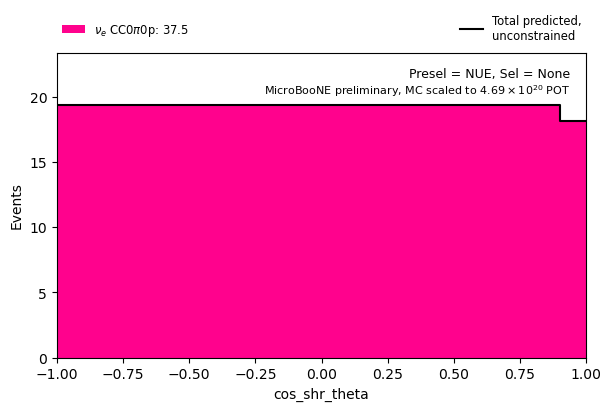

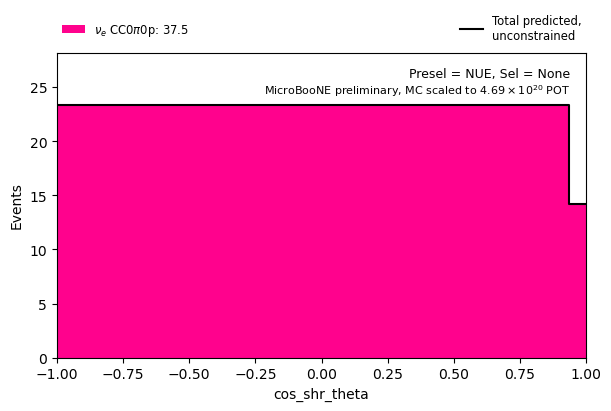

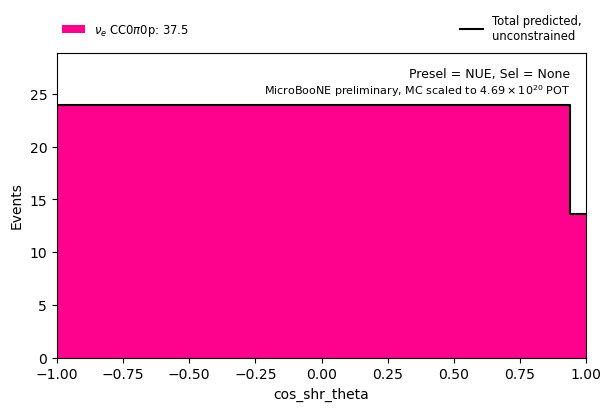

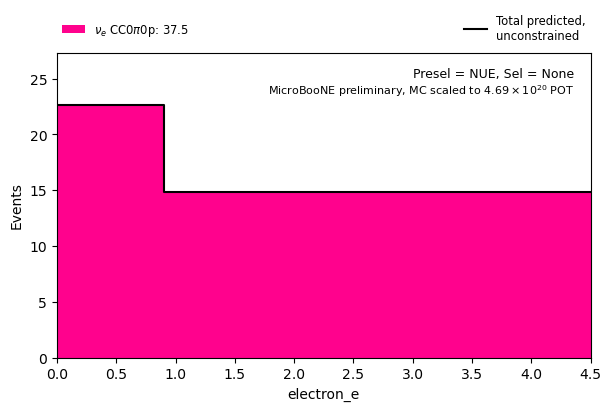

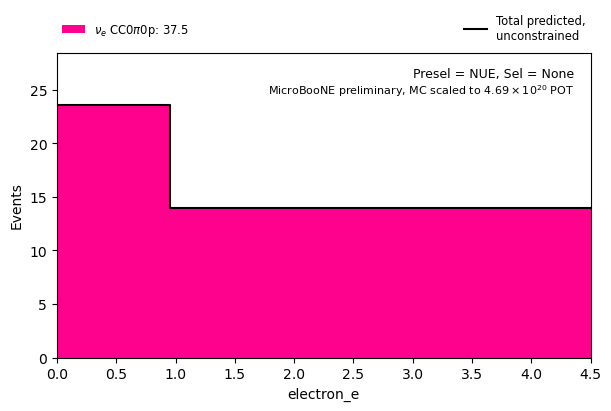

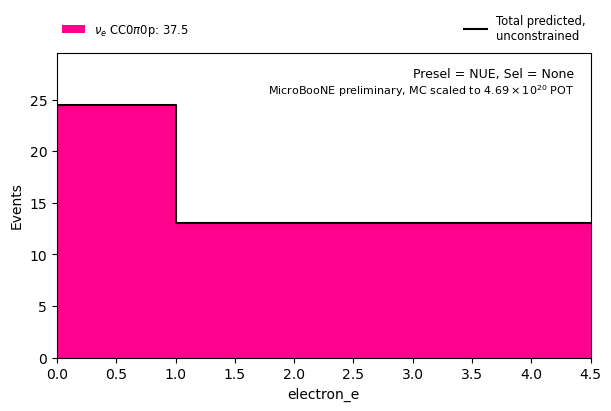

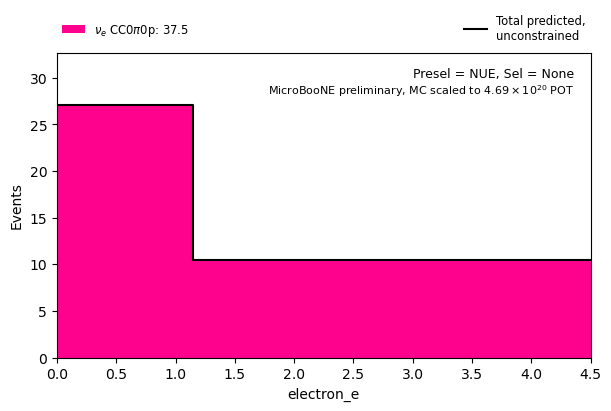

In [18]:
selection = 'None'
preselection = 'NUE'

rundata["mc"]=signal_test_nu_25p
rundata["nue"]=signal_test_nue_25p
rundata["drt"]=signal_test_dirt_25p
rundata["nc_pi0"]=signal_test_ncpi0_25p
rundata["ext"]=signal_test_ext_25p

for v in varSet:
    binning_def = v
    binning = Binning.from_config(*binning_def)
    binning.label = preselection
    binning.set_selection(selection, preselection)

    nuepresel_signal_generator = RunHistGenerator(
        rundata,
        binning,
        data_pot=data_pot,
    )

    from microfit.run_plotter import RunHistPlotter

    nuepresel_plotter = RunHistPlotter(nuepresel_signal_generator)
    
    # Blinded
    ax = nuepresel_plotter.plot(
        category_column="category",
        include_multisim_errors=False,
        add_ext_error_floor=False,
        show_data_mc_ratio=False,
        show_chi_square=False,
        show_total=False,           # Get rid of uncertainty
        title=f'Presel = {binning.preselection_key}, Sel = {binning.selection_key}',
        print_tot_pred_norm=True,
        scale_to_pot=4.69E20
    )

print_tot_pred_norm: [0.33242742 0.66757258]
print_tot_pred: [2.67255544 5.36696024]
print_tot_pred_norm: [0.45767266 0.54232734]
print_tot_pred: [3.67946651 4.36004918]
print_tot_pred_norm: [0.47902035 0.52097965]
print_tot_pred: [3.85109165 4.18842404]
print_tot_pred_norm: [0.42346625 0.57653375]
print_tot_pred: [3.40141409 4.63090032]
print_tot_pred_norm: [0.45354575 0.54645425]
print_tot_pred: [3.64302204 4.38929237]
print_tot_pred_norm: [0.48722385 0.51277615]
print_tot_pred: [3.91353517 4.11877924]
print_tot_pred_norm: [0.5815046 0.4184954]
print_tot_pred: [4.67082779 3.36148661]


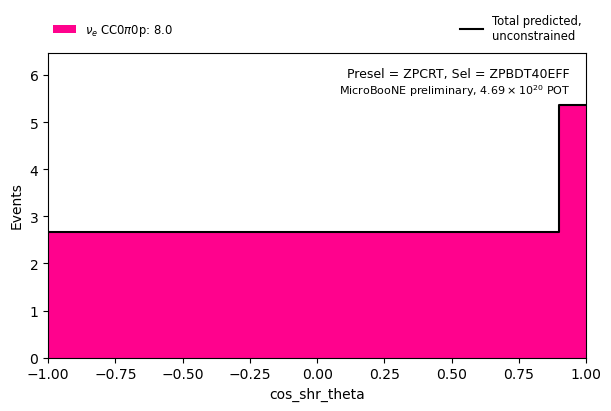

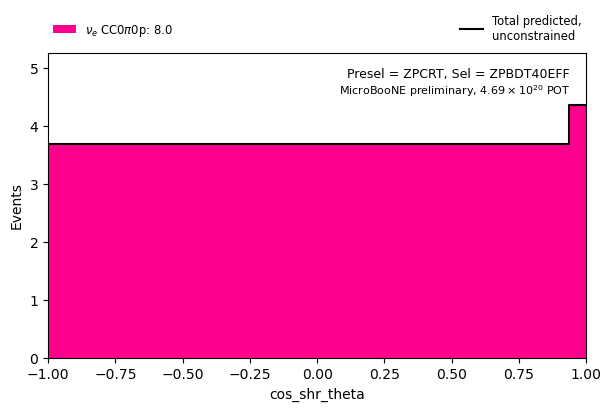

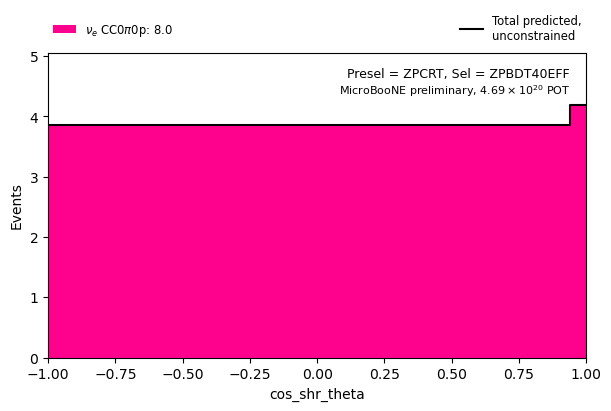

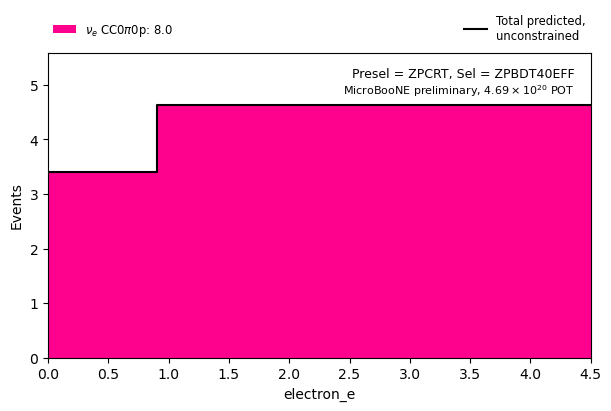

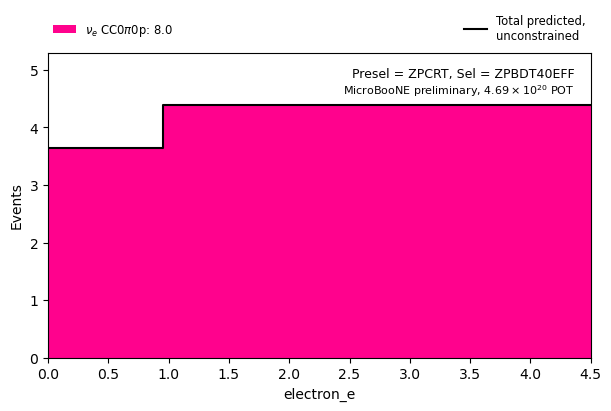

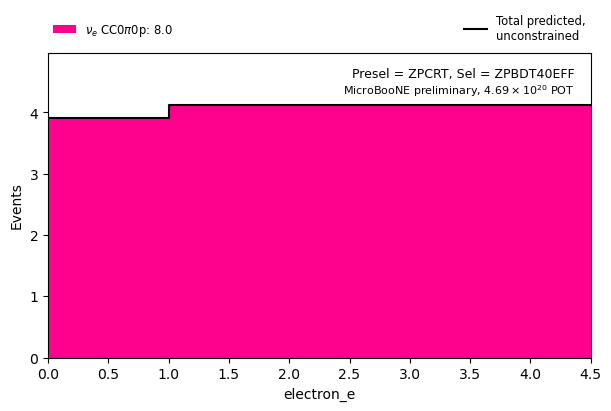

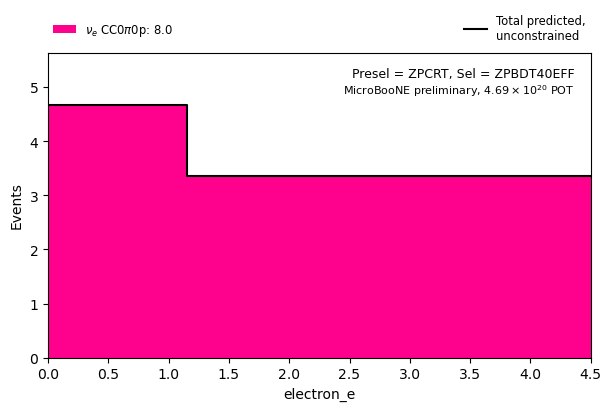

In [19]:
# preselection = 'NUE'
preselection = 'ZPCRT'

selection = 'ZPBDT40EFF'
# selection = 'ZPBDT35EFF'
# selection = 'ZPBDT30EFF'

for v in varSet:
    binning_def = v
    binning = Binning.from_config(*binning_def)
    binning.label = preselection
    binning.set_selection(selection, preselection)

    signal_signal_generator = RunHistGenerator(
        rundata,
        binning,
        data_pot=data_pot,
    )

    from microfit.run_plotter import RunHistPlotter

    signal_plotter = RunHistPlotter(signal_signal_generator)
    
    # Blinded
    ax = signal_plotter.plot(
        category_column="category",
        include_multisim_errors=False,
        add_ext_error_floor=False,
        show_data_mc_ratio=False,
        show_chi_square=False,
        show_total=False,           # Get rid of uncertainty
        title=f'Presel = {binning.preselection_key}, Sel = {binning.selection_key}',
        print_tot_pred_norm=True
    )

In [20]:
bkg_test_nu_25p = test_nu_25p.query(bkgquery)
bkg_test_nue_25p = test_nue_25p.query(bkgquery)
bkg_test_dirt_25p = test_dirt_25p.query(bkgquery)
bkg_test_ncpi0_25p = test_ncpi0_25p.query(bkgquery)
bkg_test_ext_25p = test_ext_25p.query(bkgquery)

rundata["mc"]=bkg_test_nu_25p
rundata["nue"]=bkg_test_nue_25p
rundata["drt"]=bkg_test_dirt_25p
rundata["nc_pi0"]=bkg_test_ncpi0_25p
rundata["ext"]=bkg_test_ext_25p

print_tot_pred_norm: [0.32188114 0.67811886]
print_tot_pred: [1.82867764 3.85254253]
print_tot_pred_norm: [0.47662197 0.52337803]
print_tot_pred: [2.70779437 2.97342579]
print_tot_pred_norm: [0.48873989 0.51126011]
print_tot_pred: [2.7766389  2.90458126]
print_tot_pred_norm: [0.5723381 0.4276619]
print_tot_pred: [3.25157878 2.42964138]
print_tot_pred_norm: [0.64286543 0.35713457]
print_tot_pred: [3.65226002 2.02896014]
print_tot_pred_norm: [0.65614073 0.34385927]
print_tot_pred: [3.72767992 1.95354024]
print_tot_pred_norm: [0.70550939 0.29449061]
print_tot_pred: [4.00815416 1.673066  ]


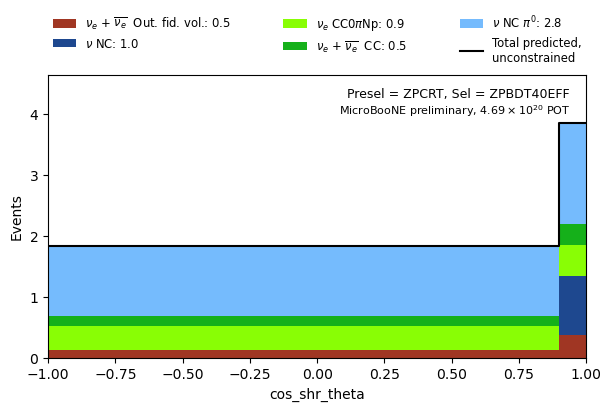

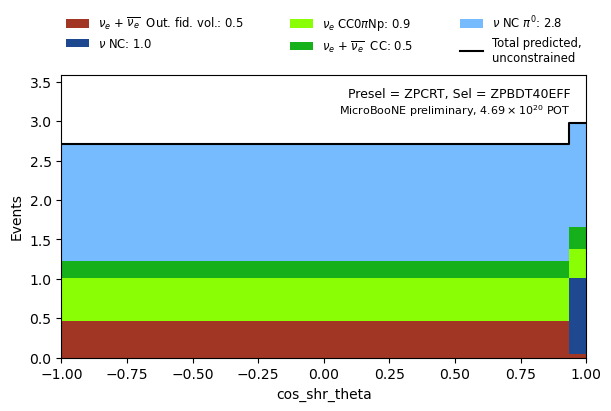

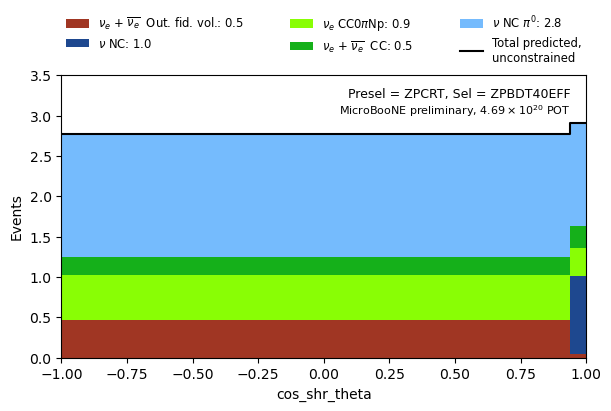

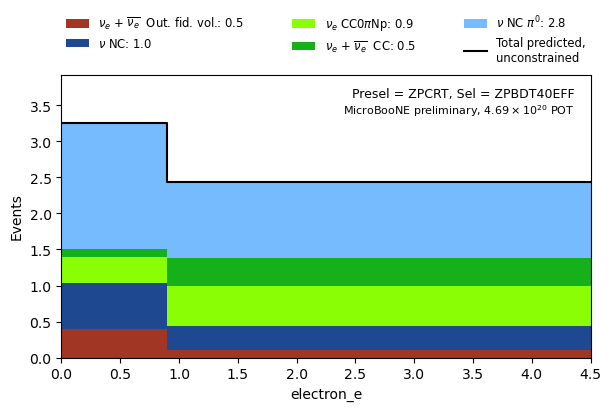

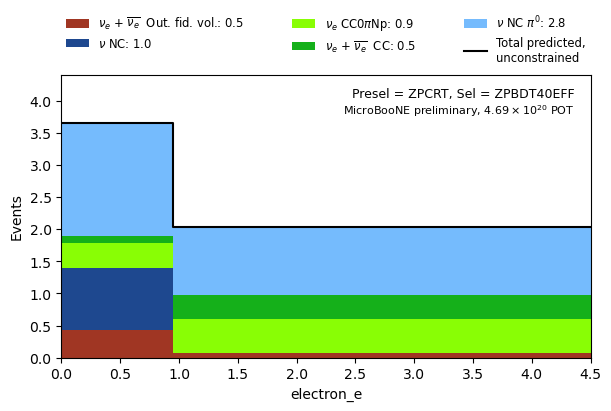

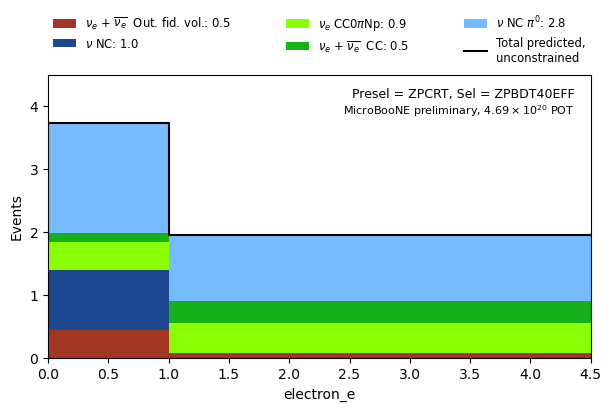

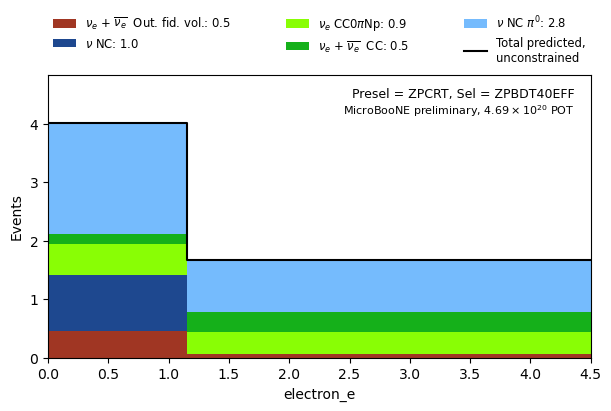

In [21]:
# preselection = 'NUE'
preselection = 'ZPCRT'

selection = 'ZPBDT40EFF'
# selection = 'ZPBDT35EFF'
# selection = 'ZPBDT30EFF'

for v in varSet:
    binning_def = v
    binning = Binning.from_config(*binning_def)
    binning.label = preselection
    binning.set_selection(selection, preselection)

    bkg_signal_generator = RunHistGenerator(
        rundata,
        binning,
        data_pot=data_pot,
    )
    
    from microfit.run_plotter import RunHistPlotter

    bkg_plotter = RunHistPlotter(bkg_signal_generator)
    
    # Blinded
    ax = bkg_plotter.plot(
        category_column="category",
        include_multisim_errors=False,
        add_ext_error_floor=False,
        show_data_mc_ratio=False,
        show_chi_square=False,
        show_total=False,           # Get rid of uncertainty
        title=f'Presel = {binning.preselection_key}, Sel = {binning.selection_key}',
        print_tot_pred_norm=True
    )

In [22]:
# import numpy as np

# # pur = np.divide(signal_signal_generator, np.add(signal_signal_generator,bkg_signal_generator))

# # pur = np.divide(signal_plotter, np.add(signal_plotter,bkg_plotter))

In [23]:
import numpy as np

if file_type == 'zppresel':
    shrangle_0_9_signal_pred_norm = [0.37904254, 0.62095746]
    shrangle_0_935_signal_pred_norm = [0.50205278, 0.49794722]
    shrangle_0_94_signal_pred_norm = [0.5221532, 0.4778468]

    shrE_0_9_signal_pred_norm = [0.46595473, 0.53404527]
    shrE_0_95_signal_pred_norm = [0.49569983, 0.50430017]
    shrE_1_signal_pred_norm = [0.52315125, 0.47684875]
    shrE_1_15_signal_pred_norm = [0.6138983, 0.3861017]
    
    shrangle_0_9_signal_pred = [6.55013391, 10.73060155]
    shrangle_0_935_signal_pred = [8.67584122, 8.60489424]
    shrangle_0_94_signal_pred = [9.02319129, 8.25754417]

    shrE_0_9_signal_pred = [8.04708342, 9.22301365]
    shrE_0_95_signal_pred = [8.56078414, 8.70931293]
    shrE_1_signal_pred = [9.03487283, 8.23522424]
    shrE_1_15_signal_pred = [10.60208321,  6.66801385]

    shrangle_0_9_bkg_pred_norm = [0.36537208, 0.63462792]
    shrangle_0_935_bkg_pred_norm = [0.49513034, 0.50486966]
    shrangle_0_94_bkg_pred_norm = [0.5162647, 0.4837353]

    shrE_0_9_bkg_pred_norm = [0.51210254, 0.48789746]
    shrE_0_95_bkg_pred_norm = [0.57300437, 0.42699563]
    shrE_1_bkg_pred_norm = [0.60425093, 0.39574907]
    shrE_1_15_bkg_pred_norm = [0.67160698, 0.32839302]
    
    shrangle_0_9_bkg_pred = [4.56584972, 7.93058868]
    shrangle_0_935_bkg_pred = [6.18736584, 6.30907257]
    shrangle_0_94_bkg_pred = [6.45147008, 6.04496833]

    shrE_0_9_bkg_pred = [6.39831045, 6.09588748]
    shrE_0_95_bkg_pred = [7.15923, 5.33496793]
    shrE_1_bkg_pred = [7.54963072, 4.94456721]
    shrE_1_15_bkg_pred = [8.39119049, 4.10300744]

if file_type == 'nuepresel':
    shrangle_0_9_signal_pred_norm = [0.38153641, 0.61846359]
    shrangle_0_935_signal_pred_norm = [0.51506482, 0.48493518]
    shrangle_0_94_signal_pred_norm = [0.53428349, 0.46571651]

    shrE_0_9_signal_pred_norm = [0.46396452, 0.53603548]
    shrE_0_95_signal_pred_norm = [0.49337887, 0.50662113]
    shrE_1_signal_pred_norm = [0.52329344, 0.47670656]
    shrE_1_15_signal_pred_norm = [0.61032626, 0.38967374]
    
    shrangle_0_9_signal_pred = [2.75724015, 4.46943618]
    shrangle_0_935_signal_pred = [3.72220673, 3.50446959]
    shrangle_0_94_signal_pred = [3.86109386, 3.36558246]

    shrE_0_9_signal_pred = [3.35162518, 3.8722574 ]
    shrE_0_95_signal_pred = [3.56411103, 3.65977155]
    shrE_1_signal_pred = [3.78021034, 3.44367225]
    shrE_1_15_signal_pred = [4.40892521, 2.81495737]

    shrangle_0_9_bkg_pred_norm = [0.46253955, 0.53746045]
    shrangle_0_935_bkg_pred_norm = [0.56116728, 0.43883272]
    shrangle_0_94_bkg_pred_norm = [0.569474, 0.430526]

    shrE_0_9_bkg_pred_norm = [0.54311095, 0.45688905]
    shrE_0_95_bkg_pred_norm = [0.59616126, 0.40383874]
    shrE_1_bkg_pred_norm = [0.61325024, 0.38674976]
    shrE_1_15_bkg_pred_norm = [0.68856728, 0.31143272]
    
    shrangle_0_9_bkg_pred = [2.33074028, 2.70826727]
    shrangle_0_935_bkg_pred = [2.82772616, 2.21128139]
    shrangle_0_94_bkg_pred = [2.86958381, 2.16942374]

    shrE_0_9_bkg_pred = [2.73674015, 2.30226739]
    shrE_0_95_bkg_pred = [3.00406109, 2.03494646]
    shrE_1_bkg_pred = [3.09017259, 1.94883495]
    shrE_1_15_bkg_pred = [3.46969572, 1.56931182]
    
# Signal Prediction for Nue Preselection, only runs 4d and 5 POT
# shrangle_0_9_signal_pred_norm_nue = [0.52902304, 0.47097696]
# shrangle_0_935_signal_pred_norm_nue = [0.6374288, 0.3625712]
# shrangle_0_94_signal_pred_norm_nue = [0.6528833, 0.3471167]

# shrE_0_9_signal_pred_norm_nue = [0.60742949, 0.39257051]
# shrE_0_95_signal_pred_norm_nue = [0.63483597, 0.36516403]
# shrE_1_signal_pred_norm_nue = [0.65815428, 0.34184572]
# shrE_1_15_signal_pred_norm_nue = [0.72502267, 0.27497733]

# shrangle_0_9_signal_pred_nue = [9.4238055, 8.38979565]
# shrangle_0_935_signal_pred_nue = [11.35490246, 6.45869869]
# shrangle_0_94_signal_pred_nue = [11.63020267, 6.18339848]

# shrE_0_9_signal_pred_nue = [10.81579109, 6.99004704]
# shrE_0_95_signal_pred_nue = [11.30378648, 6.50205165]
# shrE_1_signal_pred_nue = [11.71898853, 6.0868496 ]
# shrE_1_15_signal_pred_nue = [12.90963636, 4.89620177]

# Signal Prediction for Nue Preselection, scaled to full runs 4 and 5 POT (4.69E20)
shrangle_0_9_signal_pred_norm_nue = [0.52902304, 0.47097696]
shrangle_0_935_signal_pred_norm_nue = [0.6374288, 0.3625712]
shrangle_0_94_signal_pred_norm_nue = [0.6528833, 0.3471167]

shrE_0_9_signal_pred_norm_nue = [0.60742949, 0.39257051]
shrE_0_95_signal_pred_norm_nue = [0.63483597, 0.36516403]
shrE_1_signal_pred_norm_nue = [0.65815428, 0.34184572]
shrE_1_15_signal_pred_norm_nue = [0.72502267, 0.27497733]

shrangle_0_9_signal_pred_nue = [22.51191758, 20.04183854]
shrangle_0_935_signal_pred_nue = [27.12498983, 15.42876629]
shrangle_0_94_signal_pred_nue = [27.78263665, 14.77111947]

shrE_0_9_signal_pred_nue = [25.83714164, 16.6980699]
shrE_0_95_signal_pred_nue = [27.00288218, 15.53232937]
shrE_1_signal_pred_nue = [27.99473143, 14.54048012]
shrE_1_15_signal_pred_nue = [30.83899277, 11.69621877]

In [24]:
shrangle_0_9_pur = np.divide(shrangle_0_9_signal_pred, np.add(shrangle_0_9_signal_pred, shrangle_0_9_bkg_pred))
shrangle_0_935_pur = np.divide(shrangle_0_935_signal_pred, np.add(shrangle_0_935_signal_pred, shrangle_0_935_bkg_pred))
shrangle_0_94_pur = np.divide(shrangle_0_94_signal_pred, np.add(shrangle_0_94_signal_pred, shrangle_0_94_bkg_pred))

shrE_0_9_pur = np.divide(shrE_0_9_signal_pred, np.add(shrE_0_9_signal_pred, shrE_0_9_bkg_pred))
shrE_0_95_pur = np.divide(shrE_0_95_signal_pred, np.add(shrE_0_95_signal_pred, shrE_0_95_bkg_pred))
shrE_1_pur = np.divide(shrE_1_signal_pred, np.add(shrE_1_signal_pred, shrE_1_bkg_pred))
shrE_1_15_pur = np.divide(shrE_1_15_signal_pred, np.add(shrE_1_15_signal_pred, shrE_1_15_bkg_pred))

shrangle_pur = [shrangle_0_9_pur, shrangle_0_935_pur, shrangle_0_94_pur]
shrE_pur = [shrE_0_9_pur, shrE_0_95_pur, shrE_1_pur, shrE_1_15_pur]

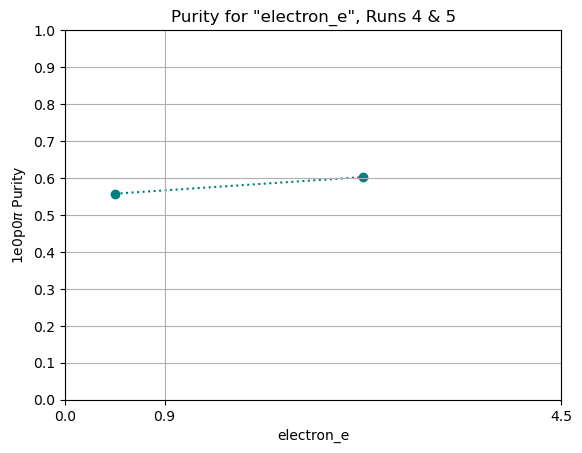

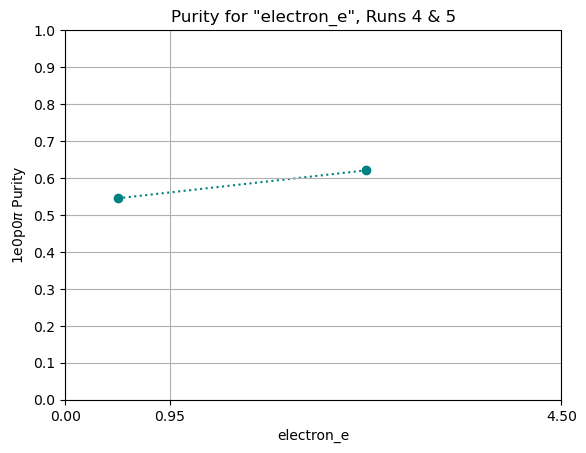

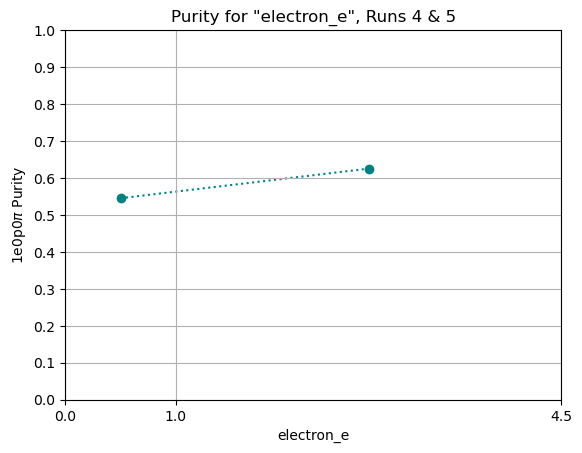

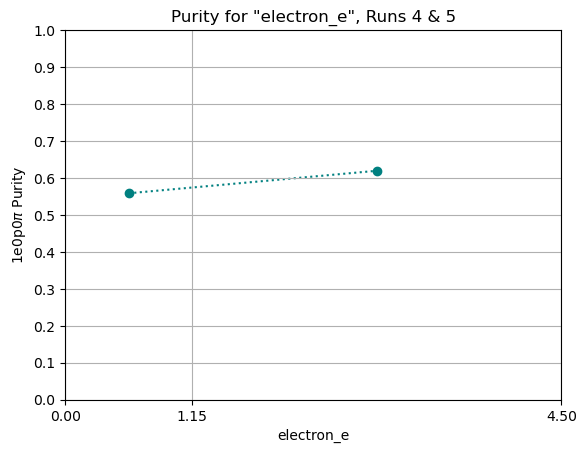

In [25]:
import matplotlib.pyplot as plt

shrE_split = [0.9, 0.95, 1, 1.15]
shrE_max = 4.5

for i in range(len(shrE_split)):
    x = (shrE_split[i]/2, (shrE_max+shrE_split[i])/2)
    y = shrE_pur[i]

    plt.scatter(x, y, color='teal')
    plt.plot(x, y, linestyle=':', zorder=1, color='teal')
    plt.xlim(0, 4.5)
    plt.ylim(0, 1)
    plt.xticks([0, shrE_split[i], 4.5])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('electron_e')
    plt.ylabel(r"1e0p0$\pi$ Purity")
    if file_type == 'zppresel':
        plt.title('Purity for "electron_e", Runs 4 & 5')
    if file_type == 'nuepresel':
            plt.title('Purity for "electron_e", Runs 4d & 5')
    plt.show()

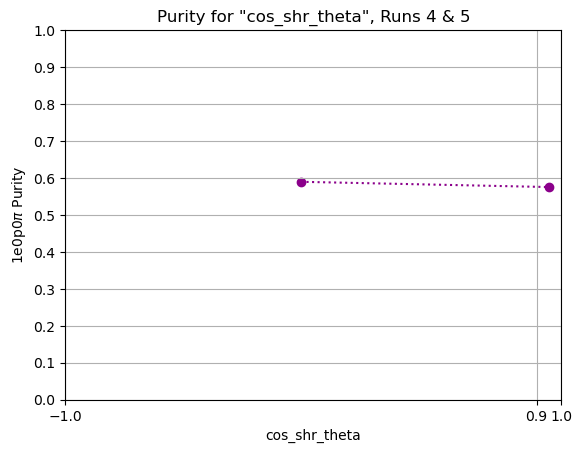

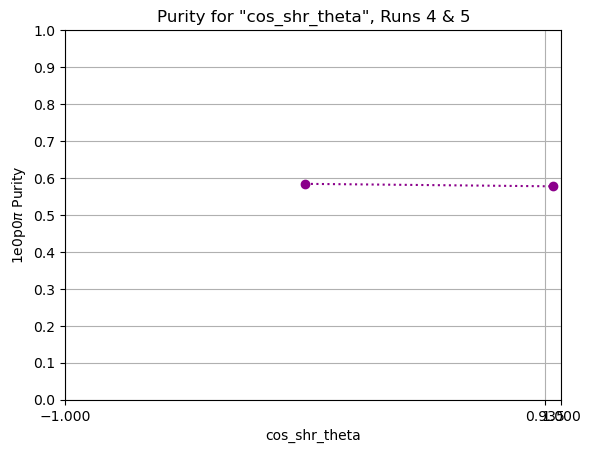

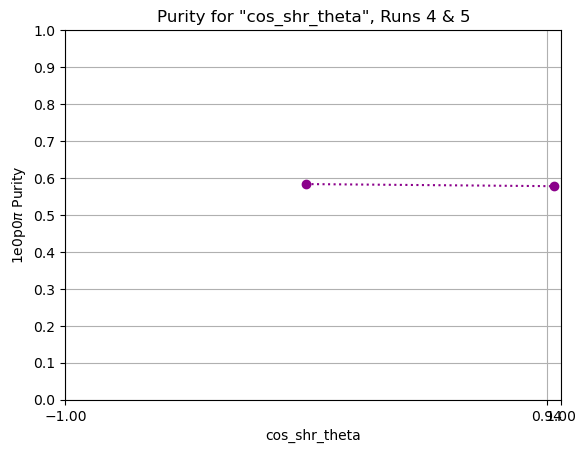

In [26]:
shrangle_split = [0.9, 0.935, 0.94]
shrangle_max = 1
shrangle_min = -1

for i in range(len(shrangle_split)):
    x = ((shrangle_split[i]+shrangle_min)/2, (shrangle_max+shrangle_split[i])/2)
    y = shrangle_pur[i]

    plt.scatter(x, y, color='darkmagenta')
    plt.plot(x, y, linestyle=':', zorder=1, color='darkmagenta')
    plt.xlim(-1, 1)
    plt.ylim(0, 1)
    plt.xticks([-1, shrangle_split[i], 1])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('cos_shr_theta')
    plt.ylabel(r"1e0p0$\pi$ Purity")
    if file_type == 'zppresel':
        plt.title('Purity for "cos_shr_theta", Runs 4 & 5')
    if file_type == 'nuepresel':
        plt.title('Purity for "cos_shr_theta", Runs 4d & 5')
    plt.show()

In [27]:
shrE_0_9_eff = np.divide(shrE_0_9_signal_pred, shrE_0_9_signal_pred_nue)
shrE_0_95_eff = np.divide(shrE_0_95_signal_pred, shrE_0_95_signal_pred_nue)
shrE_1_eff = np.divide(shrE_1_signal_pred, shrE_1_signal_pred_nue)
shrE_1_15_eff = np.divide(shrE_1_15_signal_pred, shrE_1_15_signal_pred_nue)

shrangle_0_9_eff = np.divide(shrangle_0_9_signal_pred, shrangle_0_9_signal_pred_nue)
shrangle_0_935_eff = np.divide(shrangle_0_935_signal_pred, shrangle_0_935_signal_pred_nue)
shrangle_0_94_eff = np.divide(shrangle_0_94_signal_pred, shrangle_0_94_signal_pred_nue)

shrE_eff = [shrE_0_9_eff, shrE_0_95_eff, shrE_1_eff, shrE_1_15_eff]
shrangle_eff = [shrangle_0_9_eff, shrangle_0_935_eff, shrangle_0_94_eff]

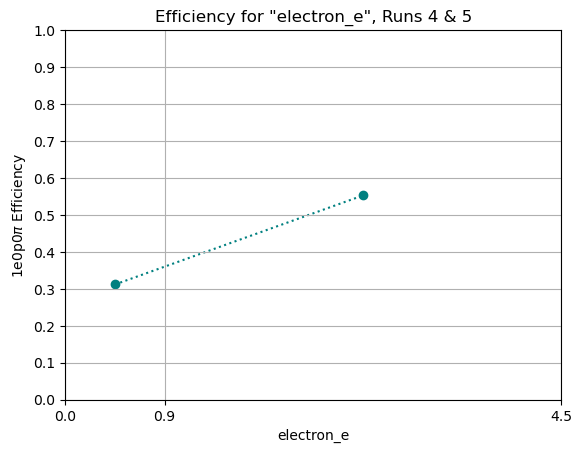

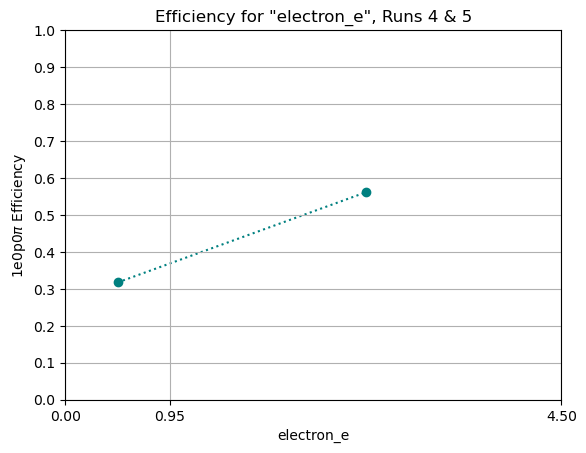

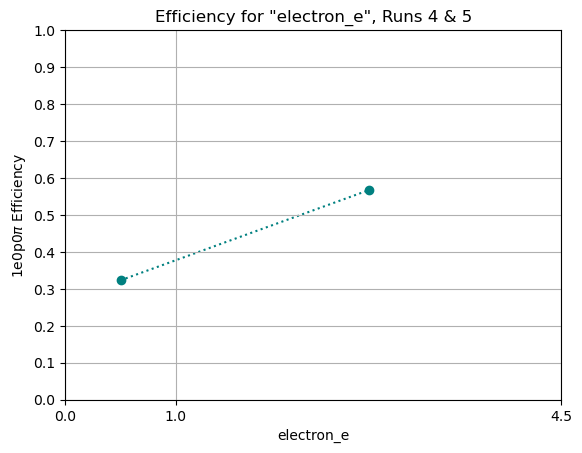

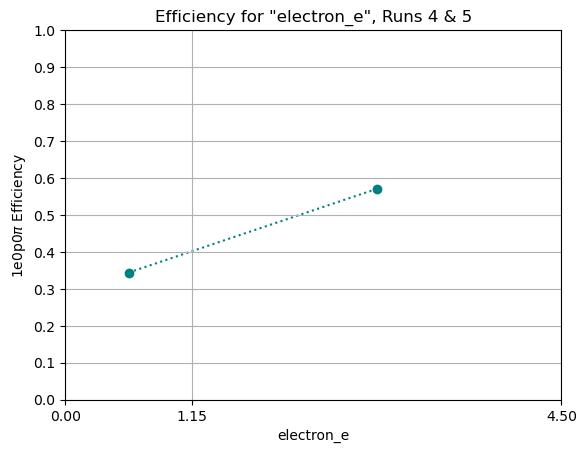

In [28]:
shrE_split = [0.9, 0.95, 1, 1.15]
shrE_max = 4.5

for i in range(len(shrE_split)):
    x = (shrE_split[i]/2, (shrE_max+shrE_split[i])/2)
    y = shrE_eff[i]

    plt.scatter(x, y, color='teal')
    plt.plot(x, y, linestyle=':', zorder=1, color='teal')
    plt.xlim(0, 4.5)
    plt.ylim(0, 1)
    plt.xticks([0, shrE_split[i], 4.5])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('electron_e')
    plt.ylabel(r"1e0p0$\pi$ Efficiency")
    if file_type == 'zppresel':
        plt.title('Efficiency for "electron_e", Runs 4 & 5')
    if file_type == 'nuepresel':
            plt.title('Efficiency for "electron_e", Runs 4d & 5')
    plt.show()

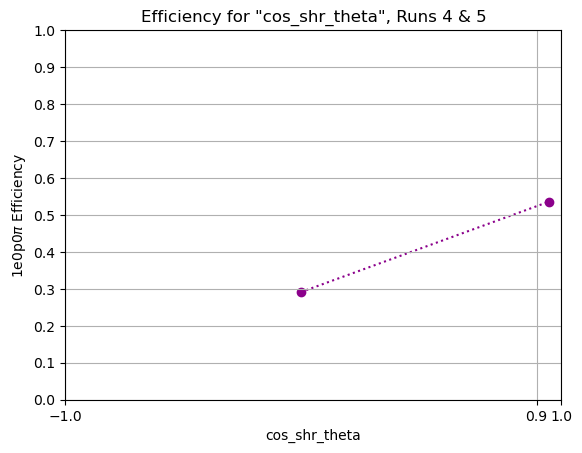

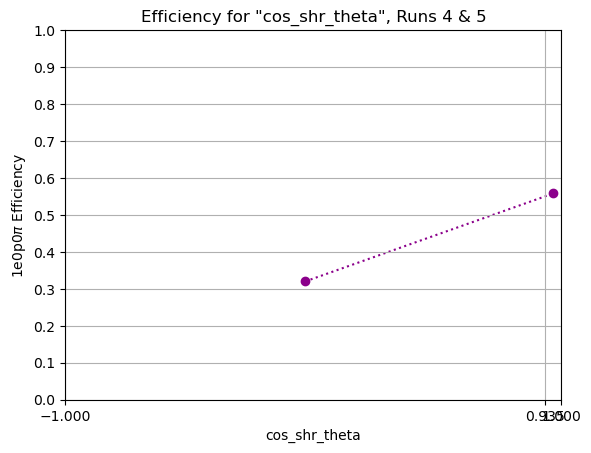

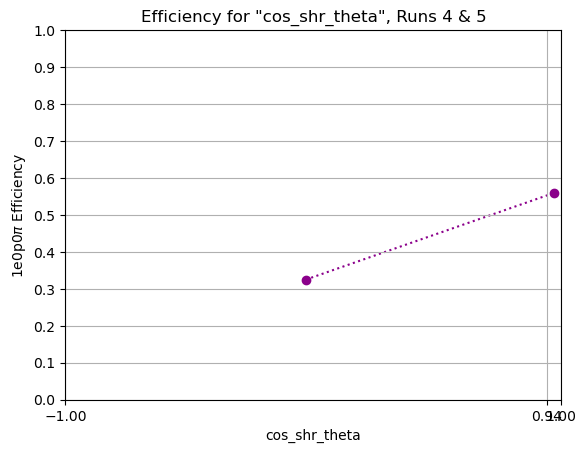

In [29]:
shrangle_split = [0.9, 0.935, 0.94]
shrangle_max = 1
shrangle_min = -1

for i in range(len(shrangle_split)):
    x = ((shrangle_split[i]+shrangle_min)/2, (shrangle_max+shrangle_split[i])/2)
    y = shrangle_eff[i]

    plt.scatter(x, y, color='darkmagenta')
    plt.plot(x, y, linestyle=':', zorder=1, color='darkmagenta')
    plt.xlim(-1, 1)
    plt.ylim(0, 1)
    plt.xticks([-1, shrangle_split[i], 1])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('cos_shr_theta')
    plt.ylabel(r"1e0p0$\pi$ Efficiency")
    if file_type == 'zppresel':
        plt.title('Efficiency for "cos_shr_theta", Runs 4 & 5')
    if file_type == 'nuepresel':
        plt.title('Efficiency for "cos_shr_theta", Runs 4d & 5')
    plt.show()

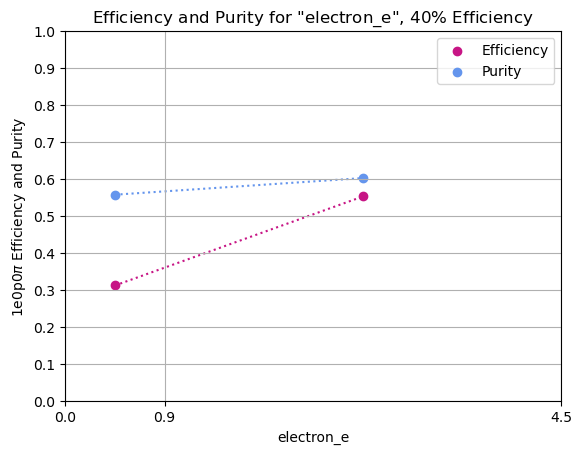

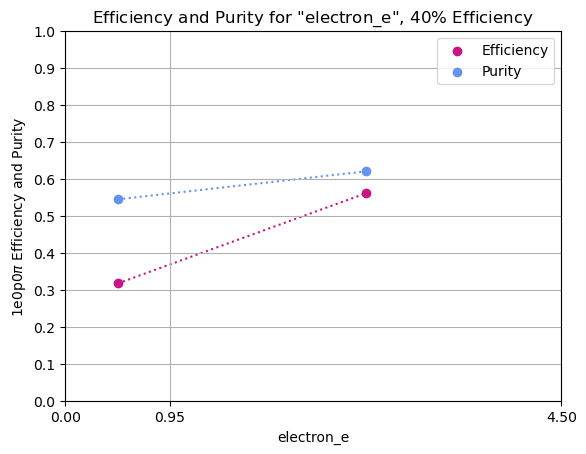

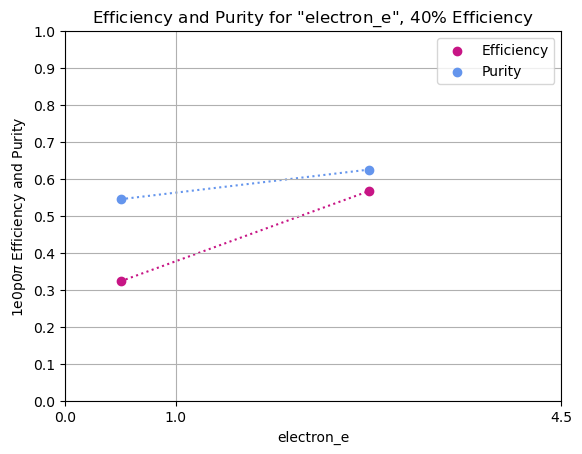

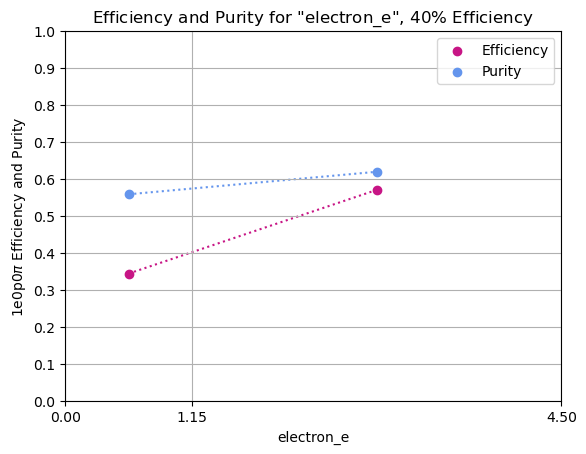

In [35]:
shrE_split = [0.9, 0.95, 1, 1.15]
shrE_max = 4.5

for i in range(len(shrE_split)):
    x = (shrE_split[i]/2, (shrE_max+shrE_split[i])/2)
    y = shrE_eff[i]
    y2 = shrE_pur[i]

    plt.scatter(x, y, color='mediumvioletred', label='Efficiency')
    plt.scatter(x, y2, color='cornflowerblue', label='Purity')
    plt.plot(x, y, linestyle=':', zorder=1, color='mediumvioletred')
    plt.plot(x, y2, linestyle=':', zorder=1, color='cornflowerblue')
    plt.xlim(0, 4.5)
    plt.ylim(0, 1)
    plt.xticks([0, shrE_split[i], 4.5])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('electron_e')
    plt.legend()
    plt.ylabel(r"1e0p0$\pi$ Efficiency and Purity")
    if file_type == 'zppresel':
        plt.title(r'Efficiency and Purity for "electron_e", 40$\%$ Efficiency')
    if file_type == 'nuepresel':
            plt.title(r'Efficiency and Purity for "electron_e", 40$\%$ Efficiency')
    plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


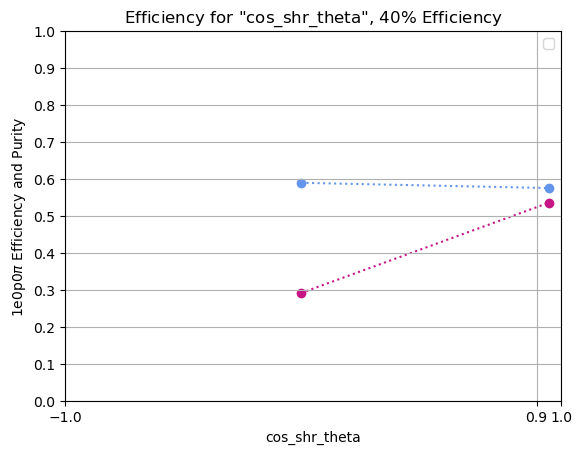

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


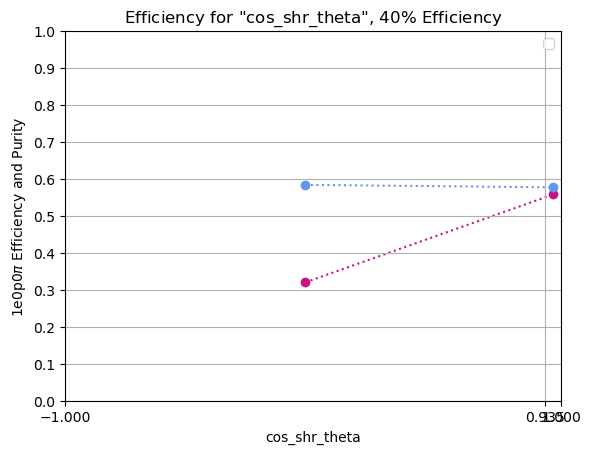

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


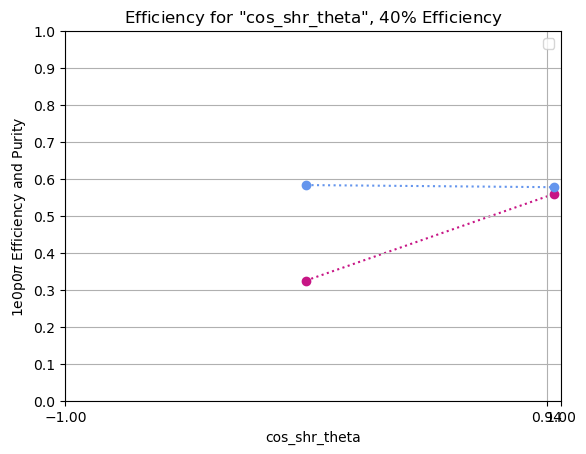

In [36]:
shrangle_split = [0.9, 0.935, 0.94]
shrangle_max = 1
shrangle_min = -1

for i in range(len(shrangle_split)):
    x = ((shrangle_split[i]+shrangle_min)/2, (shrangle_max+shrangle_split[i])/2)
    y = shrangle_eff[i]
    y2 = shrangle_pur[i]

    plt.scatter(x, y, color='mediumvioletred')
    plt.scatter(x, y2, color='cornflowerblue')
    plt.plot(x, y, linestyle=':', zorder=1, color='mediumvioletred')
    plt.plot(x, y2, linestyle=':', zorder=1, color='cornflowerblue')
    plt.xlim(-1, 1)
    plt.ylim(0, 1)
    plt.xticks([-1, shrangle_split[i], 1])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('cos_shr_theta')
    plt.ylabel(r"1e0p0$\pi$ Efficiency and Purity")
    plt.legend()
    if file_type == 'zppresel':
        plt.title(r'Efficiency for "cos_shr_theta", 40$\%$ Efficiency')
    if file_type == 'nuepresel':
        plt.title(r'Efficiency for "cos_shr_theta", 40$\%$ Efficiency')
    plt.show()

In [32]:
shrangle_effxpur_0_9 = np.multiply(shrangle_0_9_pur, shrangle_0_9_eff)
shrangle_effxpur_0_935 = np.multiply(shrangle_0_935_pur, shrangle_0_94_eff)
shrangle_effxpur_0_94 = np.multiply(shrangle_0_935_pur, shrangle_0_94_eff)

shrE_effxpur_0_9 = np.multiply(shrE_0_9_pur, shrE_0_9_eff)
shrE_effxpur_0_95 = np.multiply(shrE_0_95_pur, shrE_0_95_eff)
shrE_effxpur_1 = np.multiply(shrE_1_pur, shrE_1_eff)
shrE_effxpur_1_15 = np.multiply(shrE_1_15_pur, shrE_1_15_eff)

shrangle_effxpur = [shrangle_effxpur_0_9, shrangle_effxpur_0_935, shrangle_effxpur_0_94]
shrE_effxpur = [shrE_effxpur_0_9, shrE_effxpur_0_95, shrE_effxpur_1, shrE_effxpur_1_15]

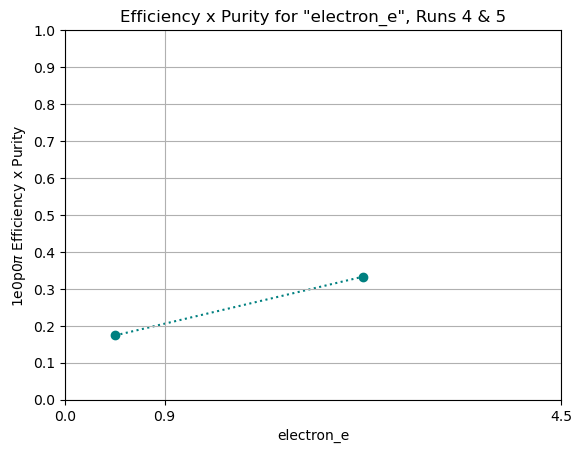

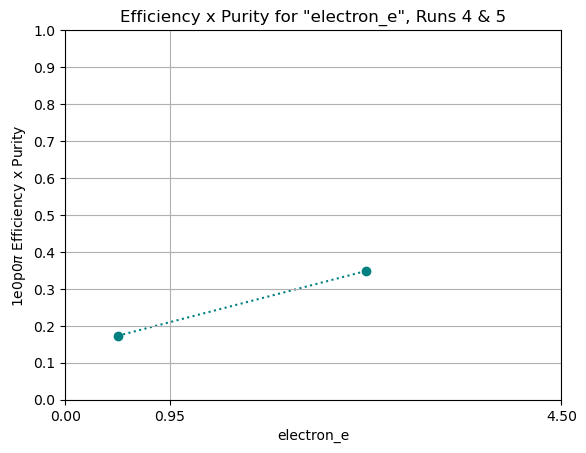

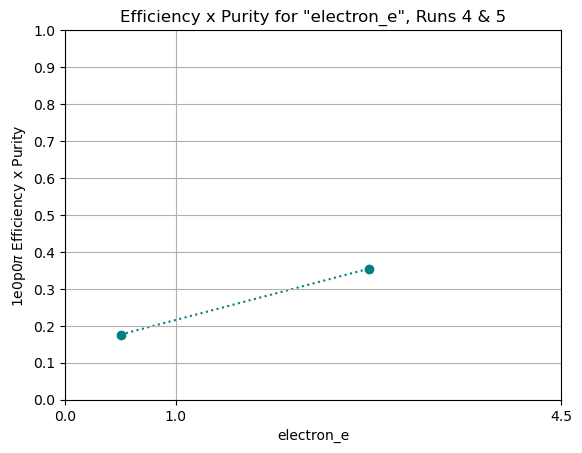

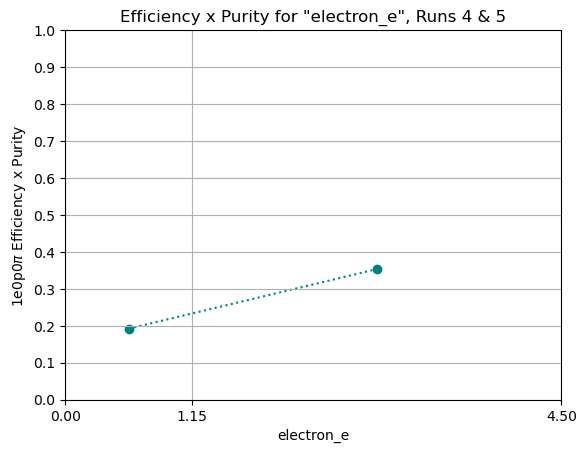

In [33]:
shrE_split = [0.9, 0.95, 1, 1.15]
shrE_max = 4.5

for i in range(len(shrE_split)):
    x = (shrE_split[i]/2, (shrE_max+shrE_split[i])/2)
    y = shrE_effxpur[i]

    plt.scatter(x, y, color='teal')
    plt.plot(x, y, linestyle=':', zorder=1, color='teal')
    plt.xlim(0, 4.5)
    plt.ylim(0, 1)
    plt.xticks([0, shrE_split[i], 4.5])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('electron_e')
    plt.ylabel(r"1e0p0$\pi$ Efficiency x Purity")
    if file_type == 'zppresel':
        plt.title('Efficiency x Purity for "electron_e", Runs 4 & 5')
    if file_type == 'nuepresel':
            plt.title('Efficiency x Purity for "electron_e", Runs 4d & 5')
    plt.show()

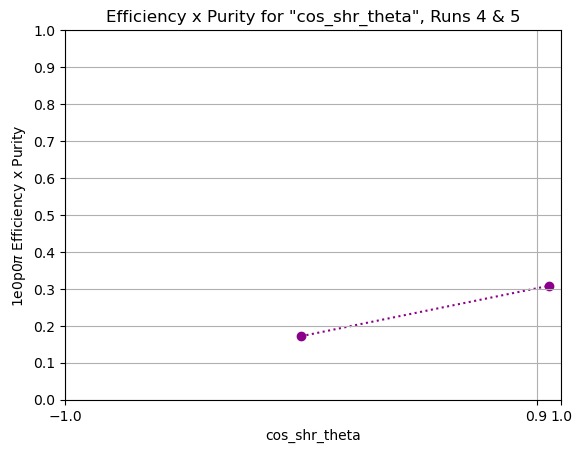

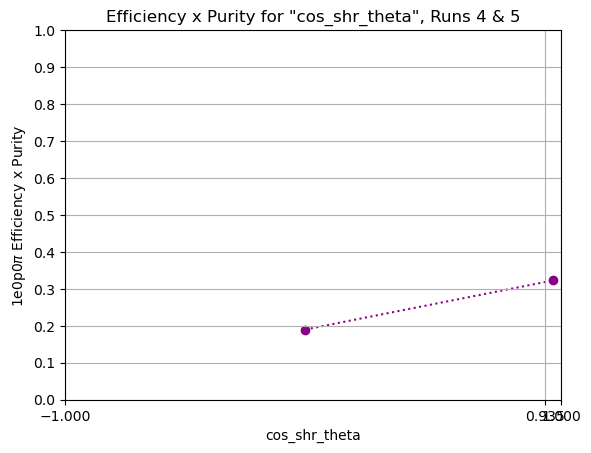

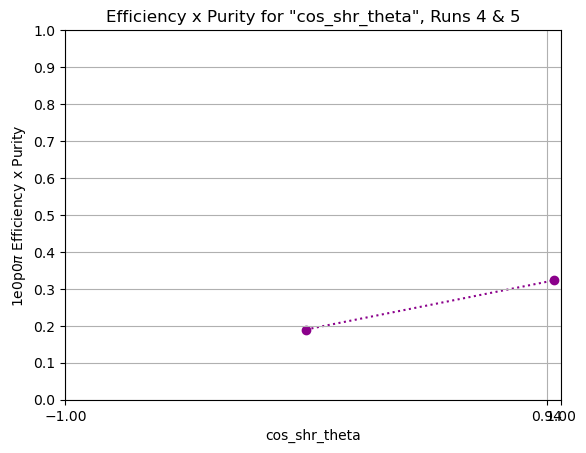

In [34]:
shrangle_split = [0.9, 0.935, 0.94]
shrangle_max = 1
shrangle_min = -1

for i in range(len(shrangle_split)):
    x = ((shrangle_split[i]+shrangle_min)/2, (shrangle_max+shrangle_split[i])/2)
    y = shrangle_effxpur[i]

    plt.scatter(x, y, color='darkmagenta')
    plt.plot(x, y, linestyle=':', zorder=1, color='darkmagenta')
    plt.xlim(-1, 1)
    plt.ylim(0, 1)
    plt.xticks([-1, shrangle_split[i], 1])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('cos_shr_theta')
    plt.ylabel(r"1e0p0$\pi$ Efficiency x Purity")
    if file_type == 'zppresel':
        plt.title('Efficiency x Purity for "cos_shr_theta", Runs 4 & 5')
    if file_type == 'nuepresel':
        plt.title('Efficiency x Purity for "cos_shr_theta", Runs 4d & 5')
    plt.show()